<a href="https://colab.research.google.com/github/Josephbello64/nigeria-health-facilities-sql/blob/main/nigeria_health_facilities_sql.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
print(os.listdir('/content'))

['.config', 'health-facilities-in-nigeria.csv', 'sample_data']


In [4]:
import pandas as pd

df = pd.read_csv('/content/health-facilities-in-nigeria.csv')
print(df.shape)
print(df.columns.tolist())

(34139, 30)
['facility_name', 'facility_type_display', 'maternal_health_delivery_services', 'emergency_transport', 'skilled_birth_attendant', 'num_chews_fulltime', 'phcn_electricity', 'c_section_yn', 'child_health_measles_immun_calc', 'num_nurses_fulltime', 'num_nursemidwives_fulltime', 'num_doctors_fulltime', 'date_of_survey', 'facility_id', 'community', 'ward', 'management', 'improved_water_supply', 'improved_sanitation', 'vaccines_fridge_freezer', 'antenatal_care_yn', 'family_planning_yn', 'malaria_treatment_artemisinin', 'sector', 'formhub_photo_id', 'gps', 'survey_id', 'unique_lga', 'latitude', 'longitude']


In [5]:
df.iloc[:5, :8]

,facility_name,facility_type_display,maternal_health_delivery_services,emergency_transport,skilled_birth_attendant,num_chews_fulltime,phcn_electricity,c_section_yn
0,HEALTH POST KAGBANG,Health Post,True,True,False,1.0,True,False
1,Alhari Clinic,Primary Health Centre (PHC),True,True,True,4.0,True,False
2,Primary health centre umukuru okehi,Basic Health Centre / Primary Health Clinic,True,True,True,2.0,True,True
3,PHC EHOM CENTRAL,Primary Health Centre (PHC),True,False,False,2.0,False,False
4,Health post,Health Post,True,False,False,0.0,False,False


In [6]:
import sqlite3

conn = sqlite3.connect('/content/health.db')
df.to_sql('facilities', conn, if_exists='replace', index=False)

print(pd.read_sql("SELECT COUNT(*) AS total_facilities FROM facilities;", conn))

   total_facilities
0             34139


In [7]:
query = """
SELECT facility_name, facility_type_display, sector, management, unique_lga, ward
FROM facilities
LIMIT 5;
"""
pd.read_sql(query, conn)

,facility_name,facility_type_display,sector,management,unique_lga,ward
0,HEALTH POST KAGBANG,Health Post,health,public,cross_river_obudu,UKPE
1,Alhari Clinic,Primary Health Centre (PHC),health,private,nasarawa_karu,Karu
2,Primary health centre umukuru okehi,Basic Health Centre / Primary Health Clinic,health,public,rivers_etche,Okehi
3,PHC EHOM CENTRAL,Primary Health Centre (PHC),health,public,cross_river_biase,Ehom
4,Health post,Health Post,health,public,cross_river_biase,Umon north


In [8]:
query = """
SELECT facility_type_display, COUNT(*) AS how_many
FROM facilities
GROUP BY facility_type_display
ORDER BY how_many DESC;
"""
pd.read_sql(query, conn)

,facility_type_display,how_many
0,Primary Health Center,8059
1,Health Post,7540
2,Primary Health Centre (PHC),5015
3,Clinic,4802
4,Basic Health Centre or Primary Health Clinic,2530
5,District / General Hospital,1728
6,Dispensary,1530
7,Teaching / Specialist Hospital,664
8,Specialist Hospital,640
9,Basic Health Centre / Primary Health Clinic,358


In [9]:
import sqlite3

conn = sqlite3.connect('/content/health.db')
df.to_sql('facilities', conn, if_exists='replace', index=False)

print(pd.read_sql("SELECT COUNT(*) AS total_facilities FROM facilities;", conn))

query = """
SELECT facility_type_display, COUNT(*) AS how_many
FROM facilities
GROUP BY facility_type_display
ORDER BY how_many DESC;
"""
display(pd.read_sql(query, conn))

query2 = """
SELECT unique_lga, ward, sector, management
FROM facilities
LIMIT 8;
"""
display(pd.read_sql(query2, conn))

   total_facilities
0             34139


,facility_type_display,how_many
0,Primary Health Center,8059
1,Health Post,7540
2,Primary Health Centre (PHC),5015
3,Clinic,4802
4,Basic Health Centre or Primary Health Clinic,2530
5,District / General Hospital,1728
6,Dispensary,1530
7,Teaching / Specialist Hospital,664
8,Specialist Hospital,640
9,Basic Health Centre / Primary Health Clinic,358


,unique_lga,ward,sector,management
0,cross_river_obudu,UKPE,health,public
1,nasarawa_karu,Karu,health,private
2,rivers_etche,Okehi,health,public
3,cross_river_biase,Ehom,health,public
4,cross_river_biase,Umon north,health,public
5,bayelsa_ekeremor,3,health,private
6,cross_river_obudu,ALEGE UBANG,health,public
7,delta_warri_south,Igunu,health,private


In [10]:
query1 = """
SELECT facility_type_display, COUNT(*) AS how_many
FROM facilities
GROUP BY facility_type_display
ORDER BY how_many DESC;
"""
display(pd.read_sql(query1, conn))

query2 = """
SELECT management, COUNT(*) AS how_many
FROM facilities
GROUP BY management
ORDER BY how_many DESC;
"""
display(pd.read_sql(query2, conn))

query3 = """
SELECT substr(unique_lga, 1, instr(unique_lga, '_') - 1) AS first_word,
       COUNT(*) AS how_many
FROM facilities
GROUP BY first_word
ORDER BY first_word;
"""
display(pd.read_sql(query3, conn))

,facility_type_display,how_many
0,Primary Health Center,8059
1,Health Post,7540
2,Primary Health Centre (PHC),5015
3,Clinic,4802
4,Basic Health Centre or Primary Health Clinic,2530
5,District / General Hospital,1728
6,Dispensary,1530
7,Teaching / Specialist Hospital,664
8,Specialist Hospital,640
9,Basic Health Centre / Primary Health Clinic,358


,management,how_many
0,public,24763
1,None,4754
2,private,4189
3,faith_based,249
4,dk,184


,first_word,how_many
0,abia,794
1,adamawa,1196
2,akwa,531
3,anambra,946
4,bauchi,1072
5,bayelsa,272
6,benue,1480
7,borno,467
8,cross,962
9,delta,806


In [11]:
query = """
SELECT management, COUNT(*) AS how_many
FROM facilities
GROUP BY management
ORDER BY how_many DESC;
"""
pd.read_sql(query, conn)

,management,how_many
0,public,24763
1,None,4754
2,private,4189
3,faith_based,249
4,dk,184


In [12]:
query = """
SELECT substr(unique_lga, 1, instr(unique_lga, '_') - 1) AS first_word,
       COUNT(*) AS how_many
FROM facilities
GROUP BY first_word
ORDER BY first_word;
"""
pd.read_sql(query, conn)

,first_word,how_many
0,abia,794
1,adamawa,1196
2,akwa,531
3,anambra,946
4,bauchi,1072
5,bayelsa,272
6,benue,1480
7,borno,467
8,cross,962
9,delta,806


In [13]:
query = """
SELECT
  SUM(CASE WHEN management IS NULL THEN 1 ELSE 0 END) AS empty_values,
  SUM(CASE WHEN management = 'None' THEN 1 ELSE 0 END) AS text_none
FROM facilities;
"""
pd.read_sql(query, conn)

,empty_values,text_none
0,4754,0


In [14]:
conn.execute("DROP TABLE IF EXISTS facilities_clean;")

conn.execute("""
CREATE TABLE facilities_clean AS
SELECT
  facility_id,
  facility_name,
  CASE first_word
    WHEN 'akwa'  THEN 'Akwa Ibom'
    WHEN 'cross' THEN 'Cross River'
    WHEN 'fct'   THEN 'FCT'
    ELSE upper(substr(first_word, 1, 1)) || substr(first_word, 2)
  END AS state,
  unique_lga,
  ward,
  CASE
    WHEN facility_type_display IS NULL
      OR facility_type_display IN ('none', 'Information not available / Don''t know')
      THEN 'Unknown'
    WHEN facility_type_display IN ('Primary Health Center', 'Primary Health Centre (PHC)')
      THEN 'Primary Health Centre'
    WHEN facility_type_display IN ('Basic Health Centre or Primary Health Clinic',
                                   'Basic Health Centre / Primary Health Clinic')
      THEN 'Basic Health Centre'
    WHEN facility_type_display IN ('District Hospital or Comprehensive Health Centre',
                                   'District Hospital / Comprehensive Health Centre')
      THEN 'District Hospital / Comprehensive Health Centre'
    ELSE facility_type_display
  END AS facility_type,
  CASE WHEN management IS NULL OR management = 'dk' THEN 'unknown'
       ELSE management END AS management,
  num_doctors_fulltime, num_nurses_fulltime,
  num_nursemidwives_fulltime, num_chews_fulltime,
  phcn_electricity, improved_water_supply, improved_sanitation,
  vaccines_fridge_freezer, antenatal_care_yn, c_section_yn,
  family_planning_yn, skilled_birth_attendant, emergency_transport,
  maternal_health_delivery_services, latitude, longitude
FROM (
  SELECT *, substr(unique_lga, 1, instr(unique_lga, '_') - 1) AS first_word
  FROM facilities
);
""")
conn.commit()

display(pd.read_sql("SELECT COUNT(*) AS total FROM facilities_clean;", conn))

display(pd.read_sql("""
SELECT state, COUNT(*) AS how_many
FROM facilities_clean
GROUP BY state
ORDER BY how_many DESC
LIMIT 10;
""", conn))

display(pd.read_sql("""
SELECT facility_type, COUNT(*) AS how_many
FROM facilities_clean
GROUP BY facility_type
ORDER BY how_many DESC;
""", conn))

,total
0,34139


,state,how_many
0,Katsina,1824
1,Niger,1687
2,Benue,1480
3,Oyo,1292
4,Ogun,1273
5,Lagos,1254
6,Plateau,1248
7,Kaduna,1248
8,Osun,1229
9,Kano,1229


,facility_type,how_many
0,Primary Health Centre,13074
1,Health Post,7540
2,Clinic,4802
3,Basic Health Centre,2888
4,District / General Hospital,1728
5,Dispensary,1530
6,Teaching / Specialist Hospital,664
7,Specialist Hospital,640
8,District Hospital / Comprehensive Health Centre,393
9,Unknown,386


In [15]:
# 1. Check how the electricity column is stored
display(pd.read_sql("""
SELECT phcn_electricity, COUNT(*) AS how_many
FROM facilities_clean
GROUP BY phcn_electricity;
""", conn))

# 2. The 5 states with the fewest facilities
display(pd.read_sql("""
SELECT state, COUNT(*) AS how_many
FROM facilities_clean
GROUP BY state
ORDER BY how_many ASC
LIMIT 5;
""", conn))

# 3. Which states depend most on private facilities?
display(pd.read_sql("""
SELECT state,
       COUNT(*) AS known_management,
       SUM(CASE WHEN management = 'private' THEN 1 ELSE 0 END) AS private_count,
       ROUND(100.0 * SUM(CASE WHEN management = 'private' THEN 1 ELSE 0 END) / COUNT(*), 1) AS private_pct
FROM facilities_clean
WHERE management != 'unknown'
GROUP BY state
HAVING COUNT(*) >= 100
ORDER BY private_pct DESC
LIMIT 10;
""", conn))

# 4. Which states have the least electricity in their facilities?
display(pd.read_sql("""
SELECT state,
       COUNT(phcn_electricity) AS known_values,
       ROUND(100.0 * AVG(phcn_electricity), 1) AS pct_with_electricity
FROM facilities_clean
GROUP BY state
HAVING COUNT(phcn_electricity) >= 100
ORDER BY pct_with_electricity ASC
LIMIT 10;
""", conn))

,phcn_electricity,how_many
0,NaN,4358
1,0.0,17807
2,1.0,11974


,state,how_many
0,Bayelsa,272
1,FCT,278
2,Yobe,422
3,Borno,467
4,Ekiti,490


,state,known_management,private_count,private_pct
0,Lagos,706,364,51.6
1,Ogun,980,460,46.9
2,Imo,880,348,39.5
3,Anambra,769,262,34.1
4,Oyo,1022,301,29.5
5,Edo,608,176,28.9
6,Benue,1093,213,19.5
7,Rivers,501,97,19.4
8,Ekiti,421,81,19.2
9,Kaduna,1141,213,18.7


,state,known_values,pct_with_electricity
0,Taraba,805,8.7
1,Zamfara,720,14.2
2,Plateau,1044,16.9
3,Katsina,1774,18.0
4,Adamawa,1148,18.2
5,Borno,428,18.5
6,Nasarawa,842,19.2
7,Kebbi,800,19.3
8,Yobe,413,19.4
9,Sokoto,741,24.4


In [16]:
# National electricity share, for comparison
display(pd.read_sql("""
SELECT ROUND(100.0 * AVG(phcn_electricity), 1) AS national_pct_with_electricity
FROM facilities_clean;
""", conn))

# States with the lowest share of facilities that have a full-time doctor
display(pd.read_sql("""
SELECT state,
       COUNT(*) AS known_values,
       ROUND(100.0 * AVG(CASE WHEN num_doctors_fulltime >= 1 THEN 1.0 ELSE 0 END), 1) AS pct_with_doctor
FROM facilities_clean
WHERE num_doctors_fulltime IS NOT NULL
GROUP BY state
HAVING COUNT(*) >= 100
ORDER BY pct_with_doctor ASC
LIMIT 10;
""", conn))

# Rank all states from best to worst electricity access
display(pd.read_sql("""
SELECT state,
       ROUND(100.0 * AVG(phcn_electricity), 1) AS pct_with_electricity,
       RANK() OVER (ORDER BY AVG(phcn_electricity) DESC) AS rank_best
FROM facilities_clean
GROUP BY state
HAVING COUNT(phcn_electricity) >= 100
ORDER BY rank_best
LIMIT 10;
""", conn))

,national_pct_with_electricity
0,40.2


,state,known_values,pct_with_doctor
0,Yobe,409,4.2
1,Katsina,1661,6.0
2,Zamfara,692,6.2
3,Kebbi,771,6.7
4,Jigawa,613,7.7
5,Adamawa,1120,8.2
6,Bauchi,1049,8.2
7,Taraba,838,8.5
8,Sokoto,742,9.0
9,Kano,1172,10.8


,state,pct_with_electricity,rank_best
0,Lagos,87.4,1
1,Edo,77.4,2
2,Ogun,77.1,3
3,Anambra,74.8,4
4,Ekiti,74.0,5
5,Delta,70.3,6
6,Imo,64.2,7
7,Kwara,62.2,8
8,Rivers,61.0,9
9,Oyo,59.6,10


In [17]:
zones = {
    'North Central': ['Benue', 'Kogi', 'Kwara', 'Nasarawa', 'Niger', 'Plateau', 'FCT'],
    'North East':    ['Adamawa', 'Bauchi', 'Borno', 'Gombe', 'Taraba', 'Yobe'],
    'North West':    ['Jigawa', 'Kaduna', 'Kano', 'Katsina', 'Kebbi', 'Sokoto', 'Zamfara'],
    'South East':    ['Abia', 'Anambra', 'Ebonyi', 'Enugu', 'Imo'],
    'South South':   ['Akwa Ibom', 'Bayelsa', 'Cross River', 'Delta', 'Edo', 'Rivers'],
    'South West':    ['Ekiti', 'Lagos', 'Ogun', 'Ondo', 'Osun', 'Oyo'],
}
rows = [(state, zone) for zone, states in zones.items() for state in states]

conn.execute("DROP TABLE IF EXISTS zones;")
conn.execute("CREATE TABLE zones (state TEXT, zone TEXT);")
conn.executemany("INSERT INTO zones VALUES (?, ?);", rows)
conn.commit()

# Safety check: the join must not lose any facilities
display(pd.read_sql("""
SELECT COUNT(*) AS joined_rows
FROM facilities_clean f
JOIN zones z ON f.state = z.state;
""", conn))

# The north-south comparison
display(pd.read_sql("""
SELECT z.zone,
       COUNT(*) AS facilities,
       ROUND(100.0 * AVG(f.phcn_electricity), 1) AS pct_electricity,
       ROUND(100.0 * AVG(CASE WHEN f.num_doctors_fulltime IS NULL THEN NULL
                              WHEN f.num_doctors_fulltime >= 1 THEN 1.0
                              ELSE 0 END), 1) AS pct_with_doctor
FROM facilities_clean f
JOIN zones z ON f.state = z.state
GROUP BY z.zone
ORDER BY pct_electricity DESC;
""", conn))

,joined_rows
0,34139


,zone,facilities,pct_electricity,pct_with_doctor
0,South West,6267,66.3,51.4
1,South East,4363,58.2,39.1
2,South South,3945,57.2,34.3
3,North Central,7713,30.6,16.9
4,North West,7282,24.4,9.3
5,North East,4569,22.6,8.9


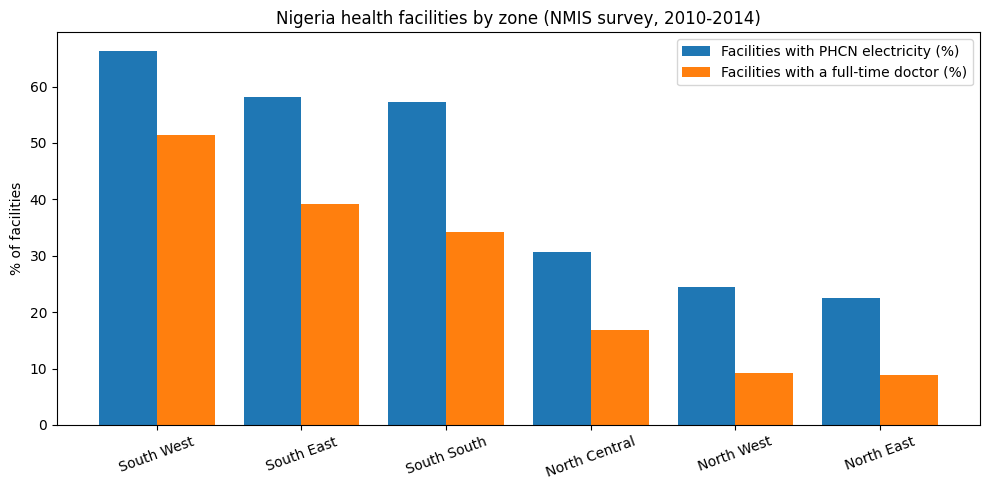

In [18]:
import matplotlib.pyplot as plt

zone_df = pd.read_sql("""
SELECT z.zone,
       ROUND(100.0 * AVG(f.phcn_electricity), 1) AS pct_electricity,
       ROUND(100.0 * AVG(CASE WHEN f.num_doctors_fulltime IS NULL THEN NULL
                              WHEN f.num_doctors_fulltime >= 1 THEN 1.0
                              ELSE 0 END), 1) AS pct_with_doctor
FROM facilities_clean f
JOIN zones z ON f.state = z.state
GROUP BY z.zone
ORDER BY pct_electricity DESC;
""", conn)

x = list(range(len(zone_df)))
width = 0.4

plt.figure(figsize=(10, 5))
plt.bar([i - width/2 for i in x], zone_df['pct_electricity'], width,
        label='Facilities with PHCN electricity (%)')
plt.bar([i + width/2 for i in x], zone_df['pct_with_doctor'], width,
        label='Facilities with a full-time doctor (%)')
plt.xticks(x, zone_df['zone'], rotation=20)
plt.ylabel('% of facilities')
plt.title('Nigeria health facilities by zone (NMIS survey, 2010-2014)')
plt.legend()
plt.tight_layout()
plt.savefig('/content/zone_gap.png', dpi=150)
plt.show()